In [ ]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv
from aicsimageio import AICSImage
from desmin_reconstruction.plotting import save_panel
from matplotlib.patches import Rectangle
from matplotlib.ticker import FormatStrFormatter
from IPython.display import display, SVG

pv.set_jupyter_backend("static")

datadir = Path("../../data/confocal")

In [2]:
img = AICSImage(datadir / "2_T32DN_denervated_desmin stainig_40X_DESMIN_image3.tif")

In [3]:
def render_xy(
    data, *, display_extent=None, height_px=1800, scalars=None, color="#CC3311"
):
    """Return (RGB screenshot, calibrated camera extent) without axes/padding.

    data must be an axis-aligned volume appropriate for an XY projection.
    display_extent is (left, right, bottom, top), similar to axes_ranges.
    It may use global coordinates even when data has a local origin.
    """
    import pyvista as pv

    x0, x1, y0, y1, z0, z1 = map(float, data.bounds)
    dx, dy = x1 - x0, y1 - y0
    if dx <= 0 or dy <= 0:
        raise ValueError("The volume must have nonzero X and Y dimensions.")
    height_px = int(height_px)
    if height_px < 2:
        raise ValueError("height_px must be at least 2.")
    width_px = max(2, int(round(height_px * dx / dy)))

    # ParallelScale is half the camera's visible height. Integer pixel counts
    # can slightly change its width, so return the actual extent of the view.
    cx, cy, cz = (x0 + x1) / 2, (y0 + y1) / 2, (z0 + z1) / 2
    half_width = (dy / 2) * width_px / height_px
    camera_extent = np.array([cx - half_width, cx + half_width, y0, y1])
    if display_extent is not None:
        left, right, bottom, top = map(float, display_extent)
        if right <= left or top <= bottom:
            raise ValueError("display_extent must have increasing limits.")
        camera_extent[:2] = left + (camera_extent[:2] - x0) * (right - left) / dx
        camera_extent[2:] = bottom + (camera_extent[2:] - y0) * (top - bottom) / dy

    pl = pv.Plotter(off_screen=True, window_size=(width_px, height_px))
    try:
        actor = pl.add_volume(
            data,
            scalars=scalars,
            cmap=[color],
            opacity=[0.0, 0.1, 0.8],
            clim=(0, 96),
            blending="maximum",
            show_scalar_bar=False,
        )
        actor.prop.interpolation_type = "linear"
        pl.set_background("black")
        pl.enable_parallel_projection()
        # Equivalent to view_xy(), with an explicit centre and tight framing.
        distance = 2 * max(dx, dy, z1 - z0)
        pl.camera_position = [(cx, cy, cz + distance), (cx, cy, cz), (0, 1, 0)]
        pl.camera.parallel_scale = dy / 2
        pl.reset_camera_clipping_range()
        rgb = np.array(pl.screenshot(transparent_background=False), copy=True)
    finally:
        pl.close()
    return rgb, tuple(camera_extent)


def compose_panel(
    overview_image,
    roi_image,
    *,
    overview_extent=(0, 222, 0, 188),
    roi_extent=(150, 222, 0, 120),
    overview_image_extent=None,
    roi_image_extent=None,
    panel_height=3.2,
    xlabel_fontsize=14,
    ylabel_fontsize=14,
    xtick_fontsize=11,
    ytick_fontsize=11,
    xtick_pad=7,
    ytick_pad=10,
    ytick_rotation=90,
    align_corner_labels=True,
    tick_format="%.1f",
):
    """Lay out tightly framed RGB images; return (fig, (overview_ax, roi_ax)).

    Panel height is in inches. Both panels have equal displayed heights and
    equal X/Y unit scaling within each panel. Their magnifications differ.
    Optional image extents account for fractional-pixel camera framing.

    Font sizes and tick padding are in points. X/Y title and tick-label sizes
    are independent. ytick_rotation can be 90 (vertical) or 0 (horizontal).
    align_corner_labels aligns the X endpoint labels inward and lifts the
    lowest Y label clear of the X labels, without changing tick values/positions.
    tick_format="%g" removes trailing .0; the default retains one decimal place.
    """
    extents = (overview_extent, roi_extent)
    image_extents = (
        overview_extent if overview_image_extent is None else overview_image_extent,
        roi_extent if roi_image_extent is None else roi_image_extent,
    )
    for x0, x1, y0, y1 in extents:
        if x1 <= x0 or y1 <= y0:
            raise ValueError("Each extent must have increasing limits.")

    widths = [panel_height * (e[1] - e[0]) / (e[3] - e[2]) for e in extents]
    left, top, gap, right = 0.75, 0.25, 0.65, 1.05
    # Reserve room for larger X tick labels and the shared X title.
    bottom = max(0.65, (xtick_pad + 1.3 * (xtick_fontsize + xlabel_fontsize) + 16) / 72)
    fw = left + sum(widths) + gap + right
    fh = bottom + panel_height + top

    with mpl.rc_context({"font.family": "sans-serif", "font.size": 11}):
        fig = plt.figure(figsize=(fw, fh), facecolor="black")
        axes = []
        xpos = left
        for rgb, extent, image_extent, width in zip(
            (overview_image, roi_image), extents, image_extents, widths
        ):
            ax = fig.add_axes(
                [xpos / fw, bottom / fh, width / fw, panel_height / fh],
                facecolor="black",
            )
            # PyVista screenshots are top-row-first; origin='upper' preserves
            # their orientation while the explicit extent makes Y increase up.
            ax.imshow(
                rgb,
                extent=image_extent,
                origin="upper",
                interpolation="none",
                aspect="equal",
            )
            ax.set_xlim(extent[:2])
            ax.set_ylim(extent[2:])
            ax.tick_params(colors="white", direction="in", length=3, width=0.7)
            ax.tick_params(axis="x", labelsize=xtick_fontsize, pad=xtick_pad)
            ax.tick_params(
                axis="y",
                labelsize=ytick_fontsize,
                labelrotation=ytick_rotation,
                pad=ytick_pad,
            )
            for name, spine in ax.spines.items():
                spine.set_visible(name in ("left", "bottom"))
                spine.set_color("white")
                spine.set_linewidth(0.7)
            ax.xaxis.set_major_formatter(FormatStrFormatter(tick_format))
            ax.yaxis.set_major_formatter(FormatStrFormatter(tick_format))
            axes.append(ax)
            xpos += width + gap

        overview, roi = axes
        overview.set_yticks(np.linspace(overview_extent[2], overview_extent[3], 5))
        roi.set_xticks(np.linspace(roi_extent[0], roi_extent[1], 3))
        roi.set_yticks(np.linspace(roi_extent[2], roi_extent[3], 5))
        for ax in axes:
            xmin, xmax = ax.get_xlim()
            ymin, _ = ax.get_ylim()
            for value, label in zip(ax.get_xticks(), ax.get_xticklabels()):
                if align_corner_labels and np.isclose(value, xmin):
                    label.set_horizontalalignment("left")
                elif align_corner_labels and np.isclose(value, xmax):
                    label.set_horizontalalignment("right")
            for value, label in zip(ax.get_yticks(), ax.get_yticklabels()):
                label.set_verticalalignment("center")
                if align_corner_labels and np.isclose(value, ymin):
                    label.set_verticalalignment("bottom")

        overview.set_ylabel(
            "y (µm)",
            color="white",
            labelpad=12,
            fontsize=ylabel_fontsize,
        )
        fig.text(
            (left + (sum(widths) + gap) / 2) / fw,
            0.25 / fh,
            "x (µm)",
            ha="center",
            va="bottom",
            color="white",
            fontsize=xlabel_fontsize,
            gid="microscopy-xlabel",
        )
        x0, x1, y0, y1 = roi_extent
        overview.add_patch(
            Rectangle(
                (x0, y0),
                x1 - x0,
                y1 - y0,
                fill=False,
                edgecolor="white",
                linewidth=0.8,
                clip_on=False,
                zorder=5,
            )
        )
    return fig, tuple(axes)


def make_panel(
    grid,
    grid_subset,
    *,
    color="#EE6677",
    overview_extent=(0, 222, 0, 188),
    roi_extent=(150, 222, 0, 120),
    height_px=1800,
    scalars=None,
    roi_scalars=None,
    xlabel_fontsize=14,
    ylabel_fontsize=14,
    xtick_fontsize=11,
    ytick_fontsize=11,
    xtick_pad=7,
    ytick_pad=10,
    ytick_rotation=90,
    align_corner_labels=True,
    tick_format="%.1f",
):
    """Render the supplied volumes and compose the two-panel figure.

    Increase height_px for more pixels in the embedded microscopy images.
    Default panel height is 3.2 inches, so 1800 pixels is about 560 ppi.
    Use scalars/roi_scalars if the desired arrays are not already active.
    Font sizes and tick padding are in points; see compose_panel for styling.
    """
    overview, overview_camera = render_xy(
        grid,
        display_extent=overview_extent,
        height_px=height_px,
        scalars=scalars,
        color=color,
    )
    roi, roi_camera = render_xy(
        grid_subset,
        display_extent=roi_extent,
        height_px=height_px,
        scalars=scalars if roi_scalars is None else roi_scalars,
        color=color,
    )
    return compose_panel(
        overview,
        roi,
        overview_extent=overview_extent,
        roi_extent=roi_extent,
        overview_image_extent=overview_camera,
        roi_image_extent=roi_camera,
        xlabel_fontsize=xlabel_fontsize,
        ylabel_fontsize=ylabel_fontsize,
        xtick_fontsize=xtick_fontsize,
        ytick_fontsize=ytick_fontsize,
        xtick_pad=xtick_pad,
        ytick_pad=ytick_pad,
        ytick_rotation=ytick_rotation,
        align_corner_labels=align_corner_labels,
        tick_format=tick_format,
    )

In [4]:
img_data = img.get_image_data("XYZ", T=0, C=0)
pixel_sizes = (
    img.physical_pixel_sizes.X,
    img.physical_pixel_sizes.Y,
    img.physical_pixel_sizes.Y,
)

In [5]:
img.physical_pixel_sizes.X * img_data.shape[0]

222.16358839050133

In [6]:
img.physical_pixel_sizes.Y * img_data.shape[1]

187.86279683377307

In [7]:
np.array(img_data.shape) + 1

array([843, 713,   2])

In [8]:
grid = pv.ImageData(dimensions=np.array(img_data.shape) + 1, spacing=pixel_sizes)
grid.cell_data["desmin"] = img_data.flatten(order="F")

In [9]:
grid

ImageData (0x14ef430ae320)
  N Cells:      599504
  N Points:     1202118
  X Bounds:     0.000e+00, 2.222e+02
  Y Bounds:     0.000e+00, 1.879e+02
  Z Bounds:     0.000e+00, 2.639e-01
  Dimensions:   843, 713, 2
  Spacing:      2.639e-01, 2.639e-01, 2.639e-01
  N Arrays:     1

In [10]:
x_vals = np.arange(img_data.shape[0]) * img.physical_pixel_sizes.X
y_vals = np.arange(img_data.shape[1]) * img.physical_pixel_sizes.Y
img_data_subset = img_data[x_vals >= 150][:, y_vals <= 120]

grid_subset = pv.ImageData(
    dimensions=np.array(img_data_subset.shape) + 1,
    spacing=pixel_sizes,
    origin=(150, 0, 0),
)
grid_subset.cell_data["desmin"] = img_data_subset.flatten(order="F")

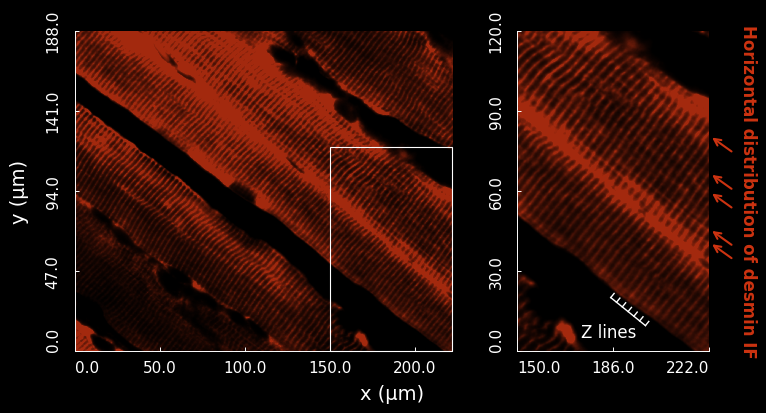

In [14]:
fig, (overview, roi) = make_panel(
    grid,
    grid_subset,
    color="#CC3311",
    overview_extent=(0, 222, 0, 188),
    roi_extent=(150, 222, 0, 120),
    height_px=1800,  # Resolution of each embedded microscopy image
)

overview.set_xticks([0, 50, 100, 150, 200])

# Annotation coordinates below are illustrative—align them to your features.
roi.text(
    1.20,
    0.50,
    "Horizontal distribution of desmin IF",
    transform=roi.transAxes,
    rotation=270,
    ha="center",
    va="center",
    color="#CC3311",
    fontsize="large",
    weight="semibold",
)

for tip_y in [80, 66, 59, 45, 40]:
    roi.annotate(
        "",
        xy=(223, tip_y),
        xytext=(14, -10),  # Tail offset; previously (7, -5)
        textcoords="offset points",
        arrowprops=dict(
            arrowstyle="->",
            color="#CC3311",
            mutation_scale=12,  # Larger arrowhead
            lw=1.5,  # Thicker shaft and arrowhead
            shrinkA=0,  # No shortening at the tail
            shrinkB=0,  # No shortening at the tip
        ),
        annotation_clip=False,
    )

# A vector baseline and short ticks for the Z-line annotation.
points = np.linspace((185, 20), (198, 9.5), 7)
delta = points[-1] - points[0]
theta = np.atan2(delta[1], delta[0]) + 0.5 * np.pi
roi.plot(points[:, 0], points[:, 1], color="white", lw=1.0)
for x, y in points:
    roi.plot(
        [x, x + 2 * np.cos(theta)], [y, y + 2 * np.sin(theta)], color="white", lw=1.0
    )
roi.text(174, 5, "Z lines", color="white", fontsize="large")
fig

In [ ]:
savepath = "../../figures/1a"
save_panel(fig, savepath, dpi=600, formats=("svg",))
display(SVG(filename=str(savepath+".svg")))
plt.close(fig)